In [1]:
# ===== Step 0: setup, load, parse dates =====
import sys
from pathlib import Path
import pandas as pd
import numpy as np

# The notebook runs from notebooks/, but config.py lives in src/.
# Walk up from the current folder until we find one that contains src/,
# then add src/ to Python's import path so `import config` works.
root = Path.cwd()
while not (root / "src").is_dir():
    if root == root.parent:                      # reached the drive root: give up
        raise FileNotFoundError("Could not find the project's src/ folder")
    root = root.parent
sys.path.insert(0, str(root / "src"))

from config import TRAIN_PATH, VALID_PATH, DECEMBER_PATH, DATE_COL

# Load as-is. We parse dates ourselves below so we can SEE any failures.
train = pd.read_csv(TRAIN_PATH)
valid = pd.read_csv(VALID_PATH)
dec   = pd.read_csv(DECEMBER_PATH)
files = {"train": train, "valid": valid, "december": dec}

# 1) Look at the raw text first. If dates were written like 03/04/2025,
#    pandas could confuse day and month, so we check the format by eye.
print("Raw date examples (text, before parsing):")
for name, df in files.items():
    print(f"  {name:<9}", df[DATE_COL].head(3).tolist())

# 2) Convert to datetime. errors="coerce" turns anything unreadable into
#    NaT ("not a time") instead of crashing, so we can count the failures.
print("\nAfter parsing:")
for name, df in files.items():
    raw_missing = df[DATE_COL].isna().sum()          # empty before parsing
    df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
    failed = df[DATE_COL].isna().sum() - raw_missing # text that would not parse
    print(f"  {name:<9} rows={len(df):>6,}  empty_before={raw_missing}  "
          f"failed_to_parse={failed}  "
          f"range={df[DATE_COL].min().date()} to {df[DATE_COL].max().date()}  "
          f"dtype={df[DATE_COL].dtype}")

Raw date examples (text, before parsing):
  train     ['2025-01-01', '2025-01-01', '2025-01-01']
  valid     ['2025-11-01', '2025-11-01', '2025-11-01']
  december  ['2025-12-01', '2025-12-02', '2025-12-03']

After parsing:
  train     rows=48,000  empty_before=0  failed_to_parse=0  range=2025-01-01 to 2025-10-31  dtype=datetime64[ns]
  valid     rows=12,000  empty_before=0  failed_to_parse=0  range=2025-11-01 to 2025-12-31  dtype=datetime64[ns]
  december  rows=    31  empty_before=0  failed_to_parse=0  range=2025-12-01 to 2025-12-31  dtype=datetime64[ns]


In [2]:
# ===== Step 1: missing values per column =====
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    """Count empty cells per column, plus text cells that are only spaces."""
    n = len(df)
    out = pd.DataFrame({
        "missing": df.isna().sum(),                      # real NaN / NaT
    })
    # Text columns could hold "" or "   ", which pandas does NOT count as missing.
    text_cols = df.select_dtypes(include="object").columns
    out["blank_text"] = 0
    for c in text_cols:
        out.loc[c, "blank_text"] = df[c].astype(str).str.strip().eq("").sum()
    out["missing_%"] = (out["missing"] / n * 100).round(2)
    return out

for name, df in files.items():
    print(f"\n=== {name}  ({len(df):,} rows) ===")
    print(missing_report(df).to_string())


=== train  (48,000 rows) ===
              missing  blank_text  missing_%
load_id             0           0       0.00
pickup              0           0       0.00
delivery            0           0       0.00
pickup_lat          0           0       0.00
pickup_lon          0           0       0.00
delivery_lat        0           0       0.00
delivery_lon        0           0       0.00
distance            0           0       0.00
equipment           0           0       0.00
weight            300           0       0.62
date                0           0       0.00
market_index      374           0       0.78
quote_signal        0           0       0.00
posted_rate         0           0       0.00

=== valid  (12,000 rows) ===
              missing  blank_text  missing_%
load_id             0           0       0.00
pickup              0           0       0.00
delivery            0           0       0.00
pickup_lat          0           0       0.00
pickup_lon          0           0       

In [4]:
# ===== Step 2: negative weights =====
pct = [0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]   # 0 = min, 1 = max

for name, df in [("train", train), ("valid", valid)]:
    w = df["weight"]
    neg = w[w < 0]
    print(f"\n=== {name} ===")
    print(f"negative: {len(neg)}   zero: {(w == 0).sum()}   "
          f"positive: {(w > 0).sum()}   missing: {w.isna().sum()}")
    if len(neg):
        print(f"smallest |negative|: {neg.abs().min():,.0f}   "
              f"largest |negative|: {neg.abs().max():,.0f}")

    # Compare the flipped negatives with the normal positive weights.
    # If they really are sign errors, the two columns should look alike.
    comp = pd.DataFrame({
        "positive": w[w > 0].quantile(pct),
        "flipped_negative": neg.abs().quantile(pct),
    })
    comp.index = [f"p{int(p*100)}" for p in pct]
    print(comp.round(0).to_string())

# Same comparison within each equipment type (train only), since a reefer
# and a flatbed might have different normal weight ranges.
print("\n=== train: median weight by equipment ===")
by_eq = pd.DataFrame({
    "pos_median": train[train.weight > 0].groupby("equipment")["weight"].median(),
    "flipped_neg_median": train[train.weight < 0].groupby("equipment")["weight"].median().abs(),
    "neg_count": train[train.weight < 0].groupby("equipment").size(),
})
print(by_eq.round(0).to_string())

print("\nDecember fixed weight:", dec["weight"].unique())


=== train ===
negative: 292   zero: 0   positive: 47408   missing: 300
smallest |negative|: 5,000   largest |negative|: 47,500
      positive  flipped_negative
p0      5000.0            5000.0
p1     12476.0           13094.0
p5     18004.0           18966.0
p25    25922.0           25928.0
p50    31494.0           31822.0
p75    37063.0           37284.0
p95    44962.0           46070.0
p99    47500.0           47500.0
p100   47500.0           47500.0

=== valid ===
negative: 145   zero: 0   positive: 11690   missing: 165
smallest |negative|: 8,229   largest |negative|: 47,500
      positive  flipped_negative
p0      5000.0            8229.0
p1     12515.0           12779.0
p5     18008.0           17436.0
p25    25746.0           26289.0
p50    31324.0           32517.0
p75    36922.0           37679.0
p95    44690.0           44558.0
p99    47500.0           47500.0
p100   47500.0           47500.0

=== train: median weight by equipment ===
           pos_median  flipped_neg_median

In [5]:
# ===== Step 3: duplicates =====
from config import ID_COL, TARGET

for name, df in [("train", train), ("valid", valid)]:
    no_id = df.drop(columns=[ID_COL])
    print(f"\n=== {name} ===")
    print(f"repeated load_id:            {df[ID_COL].duplicated().sum()}")
    print(f"fully identical rows:        {df.duplicated().sum()}")
    print(f"identical apart from load_id: {no_id.duplicated().sum()}")

# Train only: rows whose FEATURES match exactly but whose PRICE differs.
# keep=False marks every member of a duplicate group, not just the extras.
feature_cols = [c for c in train.columns if c not in (ID_COL, TARGET)]
same_features = train[train.duplicated(subset=feature_cols, keep=False)]
print(f"\ntrain rows sharing identical features with another row: {len(same_features)}")
if len(same_features):
    groups = same_features.groupby(feature_cols, dropna=False)[TARGET]
    print(f"groups: {groups.ngroups}   "
          f"groups where the price differs: {(groups.nunique() > 1).sum()}")
    print(same_features.sort_values(feature_cols).head(6).to_string())


=== train ===
repeated load_id:            0
fully identical rows:        0
identical apart from load_id: 0

=== valid ===
repeated load_id:            0
fully identical rows:        0
identical apart from load_id: 0

train rows sharing identical features with another row: 0


In [6]:
# ===== Step 4: dates, volume over time, train/validation boundary =====
for name, df in [("train", train), ("valid", valid)]:
    d = df[DATE_COL]
    print(f"\n=== {name} ===")
    print("loads per month:")
    print(d.dt.to_period("M").value_counts().sort_index().to_string())

    # Every calendar day between first and last date: is any day absent?
    all_days = pd.date_range(d.min(), d.max(), freq="D")
    per_day = d.value_counts().reindex(all_days, fill_value=0)
    print(f"days in range: {len(all_days)}   days with 0 loads: {(per_day == 0).sum()}   "
          f"loads/day min={per_day.min()} median={per_day.median():.0f} max={per_day.max()}")

    # dt.day_name() gives Monday..Sunday; reindex keeps them in week order
    week = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
    print("loads by weekday:", d.dt.day_name().value_counts().reindex(week).to_dict())

gap = (valid[DATE_COL].min() - train[DATE_COL].max()).days
print(f"\nlast train date: {train[DATE_COL].max().date()}   "
      f"first validation date: {valid[DATE_COL].min().date()}   gap: {gap} day(s)")

# First look at a price trend: median posted_rate per month (train only)
print("\ntrain median posted_rate per month:")
print(train.groupby(train[DATE_COL].dt.to_period("M"))[TARGET].median().round(0).to_string())


=== train ===
loads per month:
date
2025-01    4918
2025-02    4337
2025-03    5036
2025-04    4819
2025-05    4913
2025-06    4783
2025-07    4912
2025-08    4759
2025-09    4670
2025-10    4853
Freq: M
days in range: 304   days with 0 loads: 0   loads/day min=115 median=157 max=198
loads by weekday: {'Monday': 6769, 'Tuesday': 6737, 'Wednesday': 7007, 'Thursday': 6934, 'Friday': 6975, 'Saturday': 6770, 'Sunday': 6808}

=== valid ===
loads per month:
date
2025-11    5836
2025-12    6164
Freq: M
days in range: 61   days with 0 loads: 0   loads/day min=163 median=197 max=227
loads by weekday: {'Monday': 1703, 'Tuesday': 1846, 'Wednesday': 1747, 'Thursday': 1516, 'Friday': 1620, 'Saturday': 1823, 'Sunday': 1745}

last train date: 2025-10-31   first validation date: 2025-11-01   gap: 1 day(s)

train median posted_rate per month:
date
2025-01    1915.0
2025-02    1994.0
2025-03    2023.0
2025-04    2044.0
2025-05    2066.0
2025-06    2120.0
2025-07    2059.0
2025-08    2016.0
2025-09    2

In [7]:
# ===== Step 5: distance vs straight-line distance; city coordinates =====
def haversine_miles(lat1, lon1, lat2, lon2):
    """Straight-line distance over the Earth's surface, in miles."""
    R = 3958.8                                      # Earth's radius in miles
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))

for name, df in [("train", train), ("valid", valid)]:
    straight = haversine_miles(df.pickup_lat, df.pickup_lon,
                               df.delivery_lat, df.delivery_lon)
    ratio = df["distance"] / straight              # road miles per straight mile
    print(f"\n=== {name} ===")
    print("distance summary:", df["distance"].describe().round(1).to_dict())
    print(f"distance <= 0: {(df.distance <= 0).sum()}   "
          f"pickup == delivery: {(df.pickup == df.delivery).sum()}   "
          f"straight-line == 0: {(straight == 0).sum()}")
    print(f"road SHORTER than straight line (impossible): {(df.distance < straight).sum()}")
    print("road/straight ratio percentiles:",
          ratio.quantile([0, 0.01, 0.05, 0.5, 0.95, 0.99, 1]).round(3).to_dict())

# Does each city ALWAYS have one coordinate pair? (needed for the December lookup)
pick = train[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1)
deli = train[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1)
coords = pd.concat([pick, deli])
pairs_per_city = coords.drop_duplicates().groupby("city").size()
print(f"\ncities in train: {pairs_per_city.size}   "
      f"cities with more than one coordinate pair: {(pairs_per_city > 1).sum()}")
print(pairs_per_city[pairs_per_city > 1].head(10).to_string())


=== train ===
distance summary: {'count': 48000.0, 'mean': 1135.9, 'std': 728.6, 'min': 70.0, '25%': 550.4, '50%': 953.3, '75%': 1645.5, 'max': 3439.8}
distance <= 0: 0   pickup == delivery: 0   straight-line == 0: 0
road SHORTER than straight line (impossible): 0
road/straight ratio percentiles: {0.0: 1.058, 0.01: 1.13, 0.05: 1.143, 0.5: 1.182, 0.95: 1.273, 0.99: 1.404, 1.0: 9.635}

=== valid ===
distance summary: {'count': 12000.0, 'mean': 1141.8, 'std': 732.3, 'min': 70.0, '25%': 556.1, '50%': 953.6, '75%': 1670.5, 'max': 3325.7}
distance <= 0: 0   pickup == delivery: 0   straight-line == 0: 0
road SHORTER than straight line (impossible): 0
road/straight ratio percentiles: {0.0: 1.099, 0.01: 1.128, 0.05: 1.143, 0.5: 1.182, 0.95: 1.276, 0.99: 1.414, 1.0: 78.5}

cities in train: 64   cities with more than one coordinate pair: 0
Series([], )


In [8]:
# ===== Step 5b: inspect suspicious road/straight ratios =====
for df in (train, valid):
    df["straight"] = haversine_miles(df.pickup_lat, df.pickup_lon,
                                     df.delivery_lat, df.delivery_lon)
    df["ratio"] = df["distance"] / df["straight"]

# How many rows sit above various thresholds?
for t in [1.5, 2, 3, 5]:
    print(f"ratio > {t}:  train {(train.ratio > t).sum():>4}   valid {(valid.ratio > t).sum():>4}")

# Typical (median) road distance per lane, learned from TRAIN only
lane_median = (train.groupby(["pickup", "delivery"])["distance"]
                    .median().rename("lane_median_dist"))
print(f"\nlanes in train: {len(lane_median)}   "
      f"loads per lane: median {train.groupby(['pickup','delivery']).size().median():.0f}")

cols = ["pickup", "delivery", "distance", "straight", "ratio", "lane_median_dist"]
for name, df in [("train", train), ("valid", valid)]:
    odd = (df[df.ratio > 1.5]
             .join(lane_median, on=["pickup", "delivery"])
             .sort_values("ratio", ascending=False))
    extra = [TARGET] if TARGET in df else []
    print(f"\n=== {name}: top 12 by ratio (of {len(odd)} with ratio > 1.5) ===")
    print(odd[cols + extra].head(12).round(1).to_string())

ratio > 1.5:  train  214   valid   55
ratio > 2:  train   22   valid   16
ratio > 3:  train   12   valid   11
ratio > 5:  train   12   valid   11

lanes in train: 4014   loads per lane: median 10

=== train: top 12 by ratio (of 214 with ratio > 1.5) ===
            pickup     delivery  distance  straight  ratio  lane_median_dist  posted_rate
4140   New Orleans   Shreveport      70.0       7.3    9.6              70.0        197.1
5091   New Orleans   Shreveport      70.0       7.3    9.6              70.0        210.1
11949   Shreveport  New Orleans      70.0       7.3    9.6              70.0        213.6
12480  New Orleans   Shreveport      70.0       7.3    9.6              70.0        207.1
9348    Shreveport  New Orleans      70.0       7.3    9.6              70.0        232.3
6960   New Orleans   Shreveport      70.0       7.3    9.6              70.0        223.5
16351  New Orleans   Shreveport      70.0       7.3    9.6              70.0        216.6
15756   Shreveport  New Or

In [9]:
# ===== Step 5c: confirm the 70-mile floor; look at the suspicious coordinates =====
for name, df in [("train", train), ("valid", valid)]:
    at_floor = df.distance == 70
    above = df[~at_floor]
    print(f"=== {name} ===")
    print(f"rows with distance exactly 70: {at_floor.sum()}   "
          f"of these with ratio > 1.5: {(df.ratio[at_floor] > 1.5).sum()}")
    print(f"rows ABOVE 70 with ratio > 1.5: {(above.ratio > 1.5).sum()}   "
          f"> 2: {(above.ratio > 2).sum()}   "
          f"median straight-line miles of those > 1.5: {above.straight[above.ratio > 1.5].median():.1f}")

# Price per mile for floored vs normal rows (train): do 70-mile loads look sensible?
rpm = train[TARGET] / train["distance"]
print("\ntrain rate per mile, median: at floor "
      f"{rpm[train.distance == 70].median():.2f}   above floor {rpm[train.distance > 70].median():.2f}")

# Coordinates the data gives for the cities above + the December lane
city_xy = (pd.concat([
              train[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city","lat","lon"], axis=1),
              train[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city","lat","lon"], axis=1)])
           .drop_duplicates().set_index("city").sort_index())
check = ["New Orleans", "Shreveport", "New York", "Allentown",
         "Austin", "Lubbock", "Lexington", "Fort Wayne"]
print("\n", city_xy.reindex(check).round(3).to_string())

=== train ===
rows with distance exactly 70: 48   of these with ratio > 1.5: 27
rows ABOVE 70 with ratio > 1.5: 187   > 2: 1   median straight-line miles of those > 1.5: 56.0
=== valid ===
rows with distance exactly 70: 21   of these with ratio > 1.5: 16
rows ABOVE 70 with ratio > 1.5: 39   > 2: 1   median straight-line miles of those > 1.5: 51.7

train rate per mile, median: at floor 3.05   above floor 2.14

                 lat     lon
city                       
New Orleans  32.533 -92.195
Shreveport   32.546 -92.319
New York     40.007 -73.798
Allentown       NaN     NaN
Austin       29.396 -99.698
Lubbock      29.875 -99.855
Lexington    36.992 -84.999
Fort Wayne   41.316 -85.362


posted_rate  min=   57.22  p1=  327.17  median= 2030.76  p99= 5972.83  max=25533.00  skew=1.90  skew(log)=-0.49
rpm          min=    0.33  p1=    1.67  median=    2.15  p99=    3.18  max=   14.13  skew=8.72  skew(log)=-0.04
rate <= 0: 0

--- 8 highest rate per mile ---
            date       pickup     delivery  distance equipment   weight  market_index  posted_rate    rpm
22254 2025-05-21   Greensboro   Cincinnati     314.7    Reefer -36485.0          1.37      4445.23  14.13
36609 2025-08-20  Chattanooga      Atlanta      98.4    Reefer  22226.0          1.03      1386.42  14.09
870   2025-01-06        Tulsa  Baton Rouge     305.6    Reefer  26447.0          0.81      4069.24  13.32
17070 2025-04-18       Toledo       Dayton     201.5   Flatbed  38714.0          1.30      2609.34  12.95
27969 2025-06-25      Buffalo       Boston     589.9    Reefer  24951.0          1.34      7597.52  12.88
23369 2025-05-28     Amarillo      Lubbock     412.4   Flatbed  35494.0          1.39      530

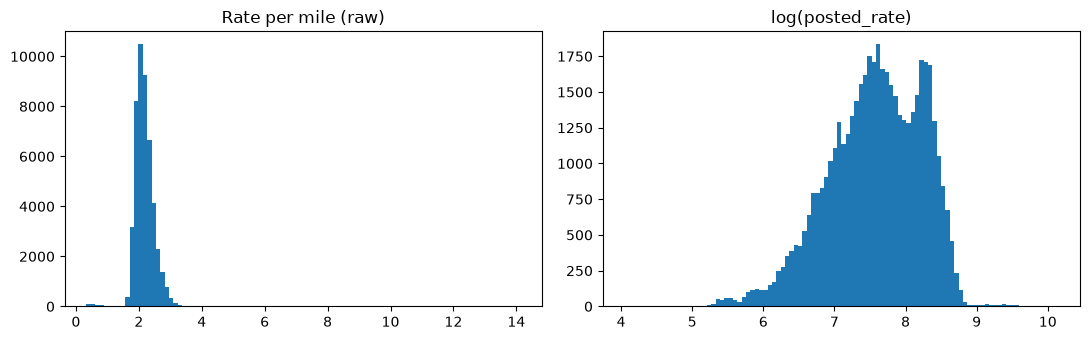

In [10]:
# ===== Step 6: posted_rate and rate per mile =====
import matplotlib.pyplot as plt

train["rpm"] = train[TARGET] / train["distance"]           # rate per mile (temporary EDA column)

# 1) Shape: skew > 1 means a long right tail; log usually pulls it toward 0
for col in [TARGET, "rpm"]:
    s = train[col]
    print(f"{col:<12} min={s.min():8.2f}  p1={s.quantile(.01):8.2f}  median={s.median():8.2f}  "
          f"p99={s.quantile(.99):8.2f}  max={s.max():8.2f}  "
          f"skew={s.skew():.2f}  skew(log)={np.log(s).skew():.2f}")
print(f"rate <= 0: {(train[TARGET] <= 0).sum()}")

# 2) Extremes: are they believable loads, or broken rows?
show = ["date", "pickup", "delivery", "distance", "equipment", "weight",
        "market_index", TARGET, "rpm"]
print("\n--- 8 highest rate per mile ---")
print(train.nlargest(8, "rpm")[show].round(2).to_string())
print("\n--- 5 lowest rate per mile ---")
print(train.nsmallest(5, "rpm")[show].round(2).to_string())

# 3) By equipment
print("\n--- by equipment ---")
print(train.groupby("equipment").agg(
        loads=(TARGET, "size"),
        median_rate=(TARGET, "median"),
        median_rpm=("rpm", "median"),
        p99_rpm=("rpm", lambda s: s.quantile(.99))).round(2).to_string())

# 4) Rate per mile by month: the trend with trip length removed
print("\n--- median rate per mile by month ---")
print(train.groupby(train[DATE_COL].dt.to_period("M"))["rpm"].median().round(3).to_string())

# 5) Histograms: raw vs log scale
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(train["rpm"], bins=100); ax[0].set_title("Rate per mile (raw)")
ax[1].hist(np.log(train[TARGET]), bins=100); ax[1].set_title("log(posted_rate)")
plt.tight_layout(); plt.show()

In [11]:
# ===== Step 6b: are extreme rates natural variation or label errors? =====
# 1) Histogram in numbers: is there a GAP between the main body and the extremes?
bins = [0, 0.5, 0.75, 1, 1.25, 1.5, 3.5, 4, 5, 7, 10, 15]
print("rows per rate-per-mile band:")
print(pd.cut(train["rpm"], bins).value_counts().sort_index().to_string())

# 2) Expected rpm = median for the same equipment + distance band (a crude "fair price")
train["dist_band"] = pd.cut(train["distance"], [0, 250, 500, 1000, 2000, 4000])
expected = train.groupby(["equipment", "dist_band"], observed=True)["rpm"].transform("median")
train["factor"] = train["rpm"] / expected        # 1.0 = priced like a typical similar load

print("\nfactor percentiles:",
      train["factor"].quantile([0, .001, .005, .01, .5, .99, .995, .999, 1]).round(2).to_dict())

low, high = train["factor"] < 0.5, train["factor"] > 2   # provisional cut-offs
print(f"\nfactor < 0.5: {low.sum()}   factor > 2: {high.sum()}   "
      f"total {low.sum() + high.sum()} ({(low.sum() + high.sum()) / len(train):.2%})")

# 3) Do the extremes cluster in time, equipment or distance? (clusters hint at real events)
for label, mask in [("LOW", low), ("HIGH", high)]:
    sub = train[mask]
    print(f"\n--- {label} (n={len(sub)}) ---")
    print("by month:     ", sub[DATE_COL].dt.month.value_counts().sort_index().to_dict())
    print("by equipment: ", sub["equipment"].value_counts().to_dict())
    print("by dist band: ", sub["dist_band"].value_counts().sort_index().to_dict())
    print("factor percentiles:", sub["factor"].quantile([0, .25, .5, .75, 1]).round(2).to_dict())

rows per rate-per-mile band:
rpm
(0.0, 0.5]        103
(0.5, 0.75]       140
(0.75, 1.0]        86
(1.0, 1.25]         7
(1.25, 1.5]         1
(1.5, 3.5]      47321
(3.5, 4.0]          2
(4.0, 5.0]         23
(5.0, 7.0]        110
(7.0, 10.0]       158
(10.0, 15.0]       49

factor percentiles: {0.0: 0.17, 0.001: 0.2, 0.005: 0.34, 0.01: 0.86, 0.5: 1.0, 0.99: 1.16, 0.995: 2.96, 0.999: 4.62, 1.0: 5.44}

factor < 0.5: 337   factor > 2: 340   total 677 (1.41%)

--- LOW (n=337) ---
by month:      {1: 40, 2: 28, 3: 37, 4: 36, 5: 37, 6: 24, 7: 29, 8: 35, 9: 30, 10: 41}
by equipment:  {'Dry Van': 171, 'Reefer': 102, 'Flatbed': 64}
by dist band:  {Interval(0, 250, closed='right'): 22, Interval(250, 500, closed='right'): 55, Interval(500, 1000, closed='right'): 120, Interval(1000, 2000, closed='right'): 90, Interval(2000, 4000, closed='right'): 50}
factor percentiles: {0.0: 0.17, 0.25: 0.22, 0.5: 0.28, 0.75: 0.35, 1.0: 0.48}

--- HIGH (n=340) ---
by month:      {1: 41, 2: 29, 3: 34, 4: 30, 5: 25


=== train ===
market_index range: {'min': 0.676, '50%': 1.056, 'max': 1.468}
distinct values per date: {113: 1, 124: 1, 127: 1, 129: 1, 130: 1, 131: 3, 132: 4, 133: 1, 134: 3, 135: 3, 136: 1, 137: 2, 138: 3, 139: 3, 140: 5, 141: 4, 142: 3, 143: 4, 144: 6, 145: 6, 146: 8, 147: 7, 148: 15, 149: 12, 150: 11, 151: 12, 152: 9, 153: 12, 154: 10, 155: 5, 156: 5, 157: 8, 158: 12, 159: 14, 160: 9, 161: 9, 162: 6, 163: 11, 164: 10, 165: 6, 166: 5, 167: 6, 168: 8, 169: 4, 170: 3, 171: 4, 172: 5, 173: 3, 174: 3, 175: 1, 176: 1, 177: 1, 178: 2, 179: 1, 180: 1, 181: 2, 182: 1, 183: 1, 185: 1, 186: 1, 187: 1, 188: 1, 195: 1}
max spread (std) within a date: 0.0295
dates where EVERY load is missing it: 0  []
missing per month: {Period('2025-01', 'M'): 36, Period('2025-02', 'M'): 36, Period('2025-03', 'M'): 44, Period('2025-04', 'M'): 31, Period('2025-05', 'M'): 43, Period('2025-06', 'M'): 42, Period('2025-07', 'M'): 36, Period('2025-08', 'M'): 33, Period('2025-09', 'M'): 31, Period('2025-10', 'M'): 42

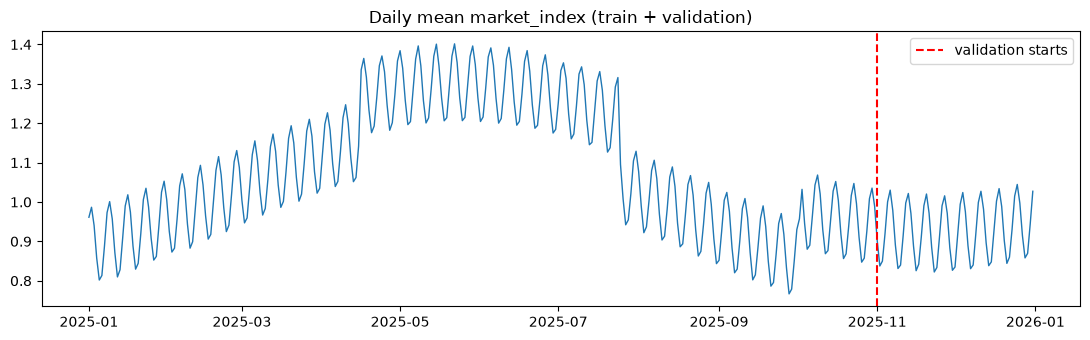

In [12]:
# ===== Step 7: market_index =====
for name, df in [("train", train), ("valid", valid)]:
    mi = df.groupby(DATE_COL)["market_index"]
    print(f"\n=== {name} ===")
    print("market_index range:", df["market_index"].describe().round(3)[["min", "50%", "max"]].to_dict())
    # nunique ignores NaN: 1 means one shared value per date
    print("distinct values per date:", mi.nunique().value_counts().sort_index().to_dict())
    print(f"max spread (std) within a date: {mi.std().max():.4f}")
    all_missing = mi.apply(lambda s: s.isna().all())
    print(f"dates where EVERY load is missing it: {all_missing.sum()}  "
          f"{list(all_missing[all_missing].index.date)[:10]}")
    print("missing per month:",
          df[df.market_index.isna()][DATE_COL].dt.to_period("M").value_counts().sort_index().to_dict())

# If values differ within a date, does equipment explain it?
per_date_eq = train.groupby([DATE_COL, "equipment"])["market_index"].nunique()
print("\ntrain: distinct values per (date, equipment):",
      per_date_eq.value_counts().sort_index().to_dict())

# Daily series for both files, then compare with daily price level (normal rows only)
both = pd.concat([train.assign(src="train"), valid.assign(src="valid")])
daily_mi = both.groupby(DATE_COL)["market_index"].mean()
normal = train[train["factor"].between(0.5, 2)]
daily_rpm = normal.groupby(DATE_COL)["rpm"].median()
joined = pd.concat([daily_mi, daily_rpm], axis=1, join="inner")
print(f"\ncorrelation daily market_index vs daily median rpm (train, normal rows): "
      f"{joined.corr().iloc[0, 1]:.3f}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(daily_mi.index, daily_mi.values, lw=1)
ax.axvline(valid[DATE_COL].min(), color="red", ls="--", label="validation starts")
ax.set_title("Daily mean market_index (train + validation)"); ax.legend()
plt.tight_layout(); plt.show()

quote_signal summary (train): {'count': 48000.0, 'mean': 2.062, 'std': 0.291, 'min': 0.692, '25%': 1.891, '50%': 2.056, '75%': 2.222, 'max': 3.61}
quote_signal summary (valid): {'count': 12000.0, 'mean': 2.051, 'std': 0.22, 'min': 1.235, '25%': 1.903, '50%': 2.051, '75%': 2.2, 'max': 2.896}

quote_signal correlations (normal rows):
              pearson  spearman
posted_rate    -0.043    -0.040
log_rate       -0.055    -0.040
rpm             0.102     0.094
factor          0.068     0.058
distance       -0.058    -0.053
market_index   -0.067    -0.050

quote_signal by group (median, std):
        median    std
HIGH     2.030  0.315
LOW      2.049  0.301
normal   2.056  0.291

by weekday (normal rows):
           market_index    rpm
date                          
Monday            0.960  2.126
Tuesday           1.035  2.139
Wednesday         1.109  2.162
Thursday          1.136  2.171
Friday            1.086  2.158
Saturday          1.005  2.132
Sunday            0.944  2.127

median fa

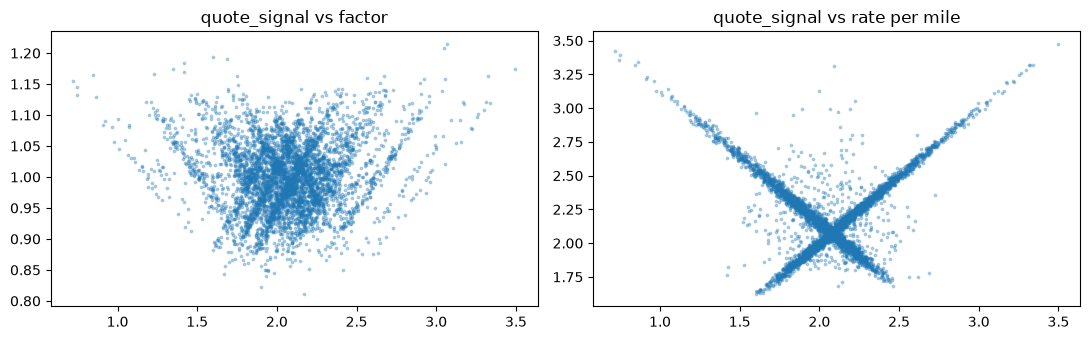

In [13]:
# ===== Step 8: quote_signal (+ follow-ups on market_index) =====
normal = train[train["factor"].between(0.5, 2)].copy()
normal["log_rate"] = np.log(normal[TARGET])

print("quote_signal summary (train):", train["quote_signal"].describe().round(3).to_dict())
print("quote_signal summary (valid):", valid["quote_signal"].describe().round(3).to_dict())

# 1) + 2) Correlations on normal rows. Spearman = rank-based, so it also catches
#         relationships that are consistent but not straight-line.
targets = [TARGET, "log_rate", "rpm", "factor", "distance", "market_index"]
corr = pd.DataFrame({
    "pearson":  [normal["quote_signal"].corr(normal[c]) for c in targets],
    "spearman": [normal["quote_signal"].corr(normal[c], method="spearman") for c in targets],
}, index=targets)
print("\nquote_signal correlations (normal rows):")
print(corr.round(3).to_string())

# 3) Does quote_signal look different on the 677 flagged rows?
grp = np.select([train["factor"] < 0.5, train["factor"] > 2], ["LOW", "HIGH"], "normal")
print("\nquote_signal by group (median, std):")
print(train.groupby(grp)["quote_signal"].agg(["median", "std"]).round(3).to_string())

# Follow-up A: weekly cycle. Median market_index and rpm by weekday (normal rows)
week = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
wd = normal.groupby(normal[DATE_COL].dt.day_name()).agg(
        market_index=("market_index", "median"), rpm=("rpm", "median")).reindex(week)
print("\nby weekday (normal rows):")
print(wd.round(3).to_string())

# Follow-up B: are rows with MISSING market_index priced differently?
miss = normal["market_index"].isna()
print(f"\nmedian factor: market_index missing {normal.factor[miss].median():.3f} (n={miss.sum()})"
      f"   present {normal.factor[~miss].median():.3f}")

# Scatter: quote_signal vs factor (sample to keep it readable)
s = normal.sample(5000, random_state=42)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(s["quote_signal"], s["factor"], s=3, alpha=.3); ax[0].set_title("quote_signal vs factor")
ax[1].scatter(s["quote_signal"], s["rpm"], s=3, alpha=.3); ax[1].set_title("quote_signal vs rate per mile")
plt.tight_layout(); plt.show()

In [14]:
# ===== Step 8b: decompose the X pattern in quote_signal =====
q, r = normal["quote_signal"], normal["rpm"]
diff, total = q - r, q + r

# The falling line has q + rpm = constant. Find that constant as the most common value
S = total.round(2).mode().iloc[0]
print(f"mirror constant S (most common q + rpm): {S}   -> crossing at {S/2:.3f}")
print("q - rpm percentiles:", diff.quantile([.01, .1, .25, .5, .75, .9, .99]).round(3).to_dict())

tol = 0.03
normal["branch"] = np.select([diff.abs() < tol, (total - S).abs() < tol],
                             ["plus", "minus"], "cloud")
print("\nbranch counts:", normal["branch"].value_counts().to_dict())

# What decides the branch? Share of each branch by month / equipment / weekday / distance
for col, key in [("month", normal[DATE_COL].dt.month),
                 ("equipment", normal["equipment"]),
                 ("weekday", normal[DATE_COL].dt.day_name()),
                 ("dist_band", normal["dist_band"])]:
    share = pd.crosstab(key, normal["branch"], normalize="index").round(3)
    print(f"\nbranch share by {col}:")
    print(share.to_string())

# Spread of quote_signal by month (compare with validation's 0.22)
print("\nquote_signal std by month, train:",
      train.groupby(train[DATE_COL].dt.month)["quote_signal"].std().round(3).to_dict())
print("quote_signal std by month, valid:",
      valid.groupby(valid[DATE_COL].dt.month)["quote_signal"].std().round(3).to_dict())

# Flagged rows: does quote_signal track the EXPECTED (true-looking) price instead of the posted one?
flag = train[~train["factor"].between(0.5, 2)].copy()
flag["expected_rpm"] = flag["rpm"] / flag["factor"]
print(f"\nflagged rows: corr(q, posted rpm) {flag.quote_signal.corr(flag.rpm):.3f}   "
      f"corr(q, expected rpm) {flag.quote_signal.corr(flag.expected_rpm):.3f}   "
      f"|q - expected| < {tol}: {((flag.quote_signal - flag.expected_rpm).abs() < tol).sum()} of {len(flag)}")

mirror constant S (most common q + rpm): 4.15   -> crossing at 2.075
q - rpm percentiles: {0.01: -1.54, 0.1: -0.619, 0.25: -0.171, 0.5: -0.009, 0.75: 0.021, 0.9: 0.174, 0.99: 0.55}

branch counts: {'plus': 20683, 'cloud': 13612, 'minus': 13028}

branch share by month:
branch  cloud  minus   plus
date                       
1       0.162  0.007  0.830
2       0.159  0.007  0.834
3       0.162  0.010  0.827
4       0.308  0.639  0.052
5       0.293  0.657  0.050
6       0.167  0.009  0.824
7       0.301  0.650  0.049
8       0.857  0.070  0.073
9       0.166  0.010  0.824
10      0.299  0.653  0.048

branch share by equipment:
branch     cloud  minus   plus
equipment                     
Dry Van    0.283  0.275  0.442
Flatbed    0.294  0.276  0.431
Reefer     0.294  0.275  0.432

branch share by weekday:
branch     cloud  minus   plus
date                          
Friday     0.298  0.281  0.421
Monday     0.272  0.251  0.477
Saturday   0.293  0.270  0.437
Sunday     0.292  0.257  0.450


In [15]:
# ===== Step 9: category consistency across files =====
def cities(df):
    return pd.concat([df["pickup"], df["delivery"]])

# 1) Exact values, shown with repr so hidden spaces are visible
for name, df in files.items():
    print(f"{name:<9} equipment: {sorted(map(repr, df['equipment'].unique()))}")
print("december  pickup/delivery:", repr(dec['pickup'].iloc[0]), repr(dec['delivery'].iloc[0]))

# 2) Do any names collapse after stripping spaces + lowercasing? (hidden variants)
for name, df in [("train", train), ("valid", valid)]:
    for col, s in [("equipment", df["equipment"]), ("cities", cities(df))]:
        raw, tidy = s.nunique(), s.str.strip().str.lower().nunique()
        print(f"{name:<6} {col:<10} distinct raw={raw:<4} after tidy={tidy:<4} "
              f"{'OK' if raw == tidy else 'VARIANTS FOUND'}")

# 3) Cities that appear only in validation
train_c, valid_c = set(cities(train)), set(cities(valid))
only_valid = sorted(valid_c - train_c)
n_rows = valid["pickup"].isin(only_valid) | valid["delivery"].isin(only_valid)
print(f"\ncities: train {len(train_c)}  valid {len(valid_c)}  "
      f"only in valid: {only_valid}  (rows affected: {n_rows.sum()})")
print(f"only in train: {sorted(train_c - valid_c)}")

# 4) Same coordinates for the same city in both files?
def city_coords(df):
    p = df[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1)
    d = df[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1)
    return pd.concat([p, d]).drop_duplicates()

vc = city_coords(valid)
print(f"valid cities with >1 coordinate pair: {(vc.groupby('city').size() > 1).sum()}")
both = city_coords(train).merge(vc, on="city", suffixes=("_tr", "_va"))
moved = both[(both.lat_tr - both.lat_va).abs().gt(1e-6) | (both.lon_tr - both.lon_va).abs().gt(1e-6)]
print(f"cities whose coordinates differ between train and valid: {len(moved)}")
print(moved.head().to_string() if len(moved) else "")

train     equipment: ["'Dry Van'", "'Flatbed'", "'Reefer'"]
valid     equipment: ["'Dry Van'", "'Flatbed'", "'Reefer'"]
december  equipment: ["'Dry Van'"]
december  pickup/delivery: 'Lexington' 'Fort Wayne'
train  equipment  distinct raw=3    after tidy=3    OK
train  cities     distinct raw=64   after tidy=64   OK
valid  equipment  distinct raw=3    after tidy=3    OK
valid  cities     distinct raw=72   after tidy=72   OK

cities: train 64  valid 72  only in valid: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']  (rows affected: 1447)
only in train: []
valid cities with >1 coordinate pair: 0
cities whose coordinates differ between train and valid: 0



In [16]:
# ===== Step 10: December lane + unseen-city range =====
lane = train[(train.pickup == "Lexington") & (train.delivery == "Fort Wayne")]
back = train[(train.pickup == "Fort Wayne") & (train.delivery == "Lexington")]
show = ["date", "distance", "equipment", "weight", "market_index", TARGET, "rpm", "factor"]

print(f"Lexington -> Fort Wayne loads in train: {len(lane)}   reverse: {len(back)}")
print(lane.sort_values(DATE_COL)[show].round(2).to_string() if len(lane) else "(none)")
if len(back):
    print("\nreverse direction:")
    print(back.sort_values(DATE_COL)[show].round(2).to_string())

# Straight-line distance from the data's own coordinates
lx = city_xy.loc["Lexington"]; fw = city_xy.loc["Fort Wayne"]
st = haversine_miles(lx.lat, lx.lon, fw.lat, fw.lon)
print(f"\nstraight-line Lexington-Fort Wayne: {st:.1f} mi   "
      f"x median ratio 1.182 = {st * 1.182:.1f} mi   (fixed December distance: 360)")

# Comparable loads: Dry Van, 330-390 miles, normal rows only -> a plausible price range
comp = train[(train.equipment == "Dry Van") & train.distance.between(330, 390)
             & train.factor.between(0.5, 2)]
print(f"\ncomparable Dry Van loads 330-390 mi: n={len(comp)}   posted_rate "
      f"p10={comp[TARGET].quantile(.1):.0f}  median={comp[TARGET].median():.0f}  "
      f"p90={comp[TARGET].quantile(.9):.0f}")
print("their median rate by month:",
      comp.groupby(comp[DATE_COL].dt.month)[TARGET].median().round(0).to_dict())

# Are the 8 validation-only cities inside the training cities' lat/lon box?
tr_box = city_xy.agg(["min", "max"])
new = city_coords(valid).set_index("city").loc[only_valid]
new["inside_box"] = (new.lat.between(*tr_box["lat"]) & new.lon.between(*tr_box["lon"]))
print("\ntraining lat/lon range:\n", tr_box.round(2).to_string())
print("\nvalidation-only cities:\n", new.round(2).to_string())

Lexington -> Fort Wayne loads in train: 32   reverse: 35
            date  distance equipment   weight  market_index  posted_rate   rpm  factor
654   2025-01-05     358.3   Dry Van  22567.0          0.80       757.93  2.12    0.91
886   2025-01-06     383.2    Reefer  36531.0          0.80       933.53  2.44    0.93
1571  2025-01-10     358.2   Dry Van  31556.0          0.87       788.08  2.20    0.95
2821  2025-01-18     362.1   Dry Van  27842.0          0.84       768.22  2.12    0.91
3913  2025-01-25     357.5   Dry Van  37102.0          0.92       807.89  2.26    0.97
6788  2025-02-12     376.8   Dry Van  41021.0          1.04       870.22  2.31    0.99
8369  2025-02-23     355.1   Dry Van  27601.0          0.96       791.25  2.23    0.96
10557 2025-03-08     359.9   Dry Van  24178.0          1.02       791.31  2.20    0.95
11817 2025-03-16     367.6   Dry Van  16195.0          0.99       806.54  2.19    0.94
12207 2025-03-19     363.1   Dry Van  27600.0          1.15       810.96 

In [17]:
# ===== Step 11 helper: settle the weight decision; count Laredo rows =====
mw = normal["weight"].isna()
print(f"median factor: weight missing {normal.factor[mw].median():.3f} (n={mw.sum()})   "
      f"present {normal.factor[~mw].median():.3f}")
print("Laredo rows in validation:",
      ((valid.pickup == "Laredo") | (valid.delivery == "Laredo")).sum())

median factor: weight missing 1.001 (n=297)   present 1.000
Laredo rows in validation: 195


In [18]:
# ===== Step 12a test: fit_cleaning on the raw training file =====
import importlib, json
import features
importlib.reload(features)          # picks up edits to features.py without restarting

raw_train = pd.read_csv(TRAIN_PATH)
learned = features.fit_cleaning(raw_train)

print("weight median:", learned["weight_median"])
print("cities learned:", len(learned["city_coords"]))
print("Lexington:", learned["city_coords"]["Lexington"],
      "  Fort Wayne:", learned["city_coords"]["Fort Wayne"])
print("saveable as JSON:", len(json.dumps(learned)) > 0)

weight median: 31496.0
cities learned: 64
Lexington: [36.99152, -84.99876]   Fort Wayne: [41.31561, -85.36206]
saveable as JSON: True


In [19]:
# ===== Step 12b test: clean train and validation =====
importlib.reload(features)
raw_valid = pd.read_csv(VALID_PATH)

for name, raw in [("train", raw_train), ("valid", raw_valid)]:
    c = features.clean(raw, learned)
    print(f"=== {name} ===")
    print(f"rows: {len(raw):,} -> {len(c):,}   same order: {raw['load_id'].equals(c['load_id'])}")
    print(f"negative weights: {(c.weight < 0).sum()}   missing weight: {c.weight.isna().sum()}   "
          f"weight range: {c.weight.min():,.0f} to {c.weight.max():,.0f}")
    print(f"missing market_index: {c.market_index.isna().sum()}   date dtype: {c[DATE_COL].dtype}")
    # Filled values should sit inside the normal range of their own date
    was_na = raw["market_index"].isna()
    print(f"filled market_index values: {was_na.sum()}, range "
          f"{c.market_index[was_na].min():.3f} to {c.market_index[was_na].max():.3f}")
    # The original must be untouched (clean works on a copy)
    print(f"original untouched: negatives still {(raw.weight < 0).sum()}, "
          f"missing weight still {raw.weight.isna().sum()}")

# Safety check: an unknown equipment value must stop the run
bad = raw_valid.head(3).copy()
bad.loc[0, "equipment"] = "Tanker"
try:
    features.clean(bad, learned)
    print("\nPROBLEM: unknown equipment was NOT caught")
except ValueError as e:
    print(f"\nunknown equipment caught as expected: {e}")

=== train ===
rows: 48,000 -> 48,000   same order: True
negative weights: 0   missing weight: 0   weight range: 5,000 to 47,500
missing market_index: 0   date dtype: datetime64[ns]
filled market_index values: 374, range 0.779 to 1.402
original untouched: negatives still 292, missing weight still 300
=== valid ===
rows: 12,000 -> 12,000   same order: True
negative weights: 0   missing weight: 0   weight range: 5,000 to 47,500
missing market_index: 0   date dtype: datetime64[ns]
filled market_index values: 249, range 0.822 to 1.045
original untouched: negatives still 145, missing weight still 165

unknown equipment caught as expected: Unknown equipment values: ['Tanker']


In [22]:
# ===== Step 12c test: December file =====
importlib.reload(features)
raw_dec = pd.read_csv(DECEMBER_PATH)

clean_valid = features.clean(raw_valid, learned)
daily = features.daily_market_index(clean_valid)
dec_clean = features.clean(raw_dec, learned, market_by_date=daily)

print(f"rows: {len(dec_clean)}   columns added: "
      f"{[c for c in dec_clean.columns if c not in raw_dec.columns]}")
print("dtypes:", dec_clean[["pickup_lat", "pickup_lon", "delivery_lat",
                            "delivery_lon", "market_index"]].dtypes.astype(str).to_dict())
mi = dec_clean.set_index(DATE_COL)["market_index"]
print(f"market_index range: {mi.min():.3f} to {mi.max():.3f}   missing: {mi.isna().sum()}")
print("matches validation's daily mean:", np.allclose(mi.values, daily.reindex(mi.index).values))
print("mean by weekday:",
      mi.groupby(mi.index.day_name()).mean()
        .reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
        .round(3).to_dict())

# The original December file must be untouched (7 columns, empty predictions)
print(f"\noriginal columns unchanged: {list(raw_dec.columns)}")
print(f"original predicted_rate still empty: {raw_dec['predicted_rate'].isna().all()}")

# Safety check: December without the market table must stop
try:
    features.clean(raw_dec, learned)
    print("PROBLEM: missing market_by_date was NOT caught")
except ValueError as e:
    print(f"missing market table caught as expected: {e}")

rows: 31   columns added: ['market_index', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']
dtypes: {'pickup_lat': 'float64', 'pickup_lon': 'float64', 'delivery_lat': 'float64', 'delivery_lon': 'float64', 'market_index': 'float64'}
market_index range: 0.831 to 1.045   missing: 0
matches validation's daily mean: True
mean by weekday: {'Monday': 0.85, 'Tuesday': 0.926, 'Wednesday': 1.007, 'Thursday': 1.032, 'Friday': 0.986, 'Saturday': 0.901, 'Sunday': 0.843}

original columns unchanged: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
original predicted_rate still empty: True
missing market table caught as expected: No market_index column: pass market_by_date


In [23]:
print("coordinates row 0:", dec_clean.loc[0, ["pickup_lat", "pickup_lon",
                                              "delivery_lat", "delivery_lon"]].round(3).to_dict())

TypeError: Expected numeric dtype, got object instead.

In [24]:
cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]
print("coordinates row 0:", dec_clean[cols].iloc[0].round(3).to_dict())
print("same for all 31 rows:", (dec_clean[cols].nunique() == 1).all())

coordinates row 0: {'pickup_lat': 36.992, 'pickup_lon': -84.999, 'delivery_lat': 41.316, 'delivery_lon': -85.362}
same for all 31 rows: True


In [25]:
# ===== Step 13: fold rehearsal + final no-gaps check =====
importlib.reload(features)
raw_train[DATE_COL] = pd.to_datetime(raw_train[DATE_COL])

# 1) Learn from Jan-Jul ONLY, then clean Aug-Oct with those values
fold_train = raw_train[raw_train[DATE_COL] < "2025-08-01"]
fold_hold  = raw_train[raw_train[DATE_COL] >= "2025-08-01"]
learned_fold = features.fit_cleaning(fold_train)
hold_clean = features.clean(fold_hold, learned_fold)

print(f"fold sizes: train {len(fold_train):,}   holdout {len(fold_hold):,}   (sum {len(fold_train)+len(fold_hold):,})")
print(f"weight median: fold-only {learned_fold['weight_median']}   full file {learned['weight_median']}")
filled = fold_hold["weight"].isna()
print(f"holdout rows with filled weight: {filled.sum()}   "
      f"all got the FOLD median: {(hold_clean.weight[filled] == learned_fold['weight_median']).all()}")
print(f"cities learned from fold: {len(learned_fold['city_coords'])}")

# 2) Final check: no gaps in any column a model could use, in all three cleaned files
model_cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
              "distance", "equipment", "weight", "date", "market_index"]
for name, c in [("train", features.clean(raw_train, learned)),
                ("valid", clean_valid), ("december", dec_clean)]:
    gaps = c[model_cols].isna().sum().sum()
    print(f"{name:<9} rows {len(c):>6,}   gaps in model columns: {gaps}")

fold sizes: train 33,718   holdout 14,282   (sum 48,000)
weight median: fold-only 31511.0   full file 31496.0
holdout rows with filled weight: 94   all got the FOLD median: True
cities learned from fold: 64
train     rows 48,000   gaps in model columns: 0
valid     rows 12,000   gaps in model columns: 0
december  rows     31   gaps in model columns: 0
